# Job Market NLP & ML Analyzer

**A data-driven analysis of the LinkedIn job postings market.**

This notebook presents the complete analytical pipeline for the Job Market Analyzer: cleaning ~33,000 job postings, then applying three machine-learning tasks to uncover structure in the labor market.

| Task | Type | Model | Metric |
|---|---|---|---|
| Salary prediction | Regression | RidgeCV (log-target) | R² = 0.645 |
| Seniority classification | Classification | LogisticRegression | Macro-F1 = 0.709 |
| Skill clustering | Unsupervised | KMeans (k=10) | 10 coherent tracks |

**Data**: `xanderios/linkedin-job-postings` (Hugging Face) — ~33k postings  
**Stack**: Python 3.10, scikit-learn, pandas, matplotlib, seaborn  
**Pipeline**: `nlp_cleaner.py` → `analysis.py` → `ml_models.py` → this notebook

*This notebook reads from saved artifacts (`reports/*.json`, `visualizations/*.png`). It does not re-train models — opens in ~5 seconds, fully reproducible.*

In [14]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

# Resolve paths robustly (works whether opened from project root or notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR    = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
VIZ_DIR     = PROJECT_ROOT / "visualizations"

for d in (DATA_DIR, REPORTS_DIR, VIZ_DIR):
    assert d.exists(), f"Missing directory: {d}"

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

print(f"Project root:   {PROJECT_ROOT}")
print(f"Reports:        {sorted(p.name for p in REPORTS_DIR.glob('*.json'))}")
print(f"Visualizations: {sorted(p.name for p in VIZ_DIR.glob('*.png'))}")

Project root:   e:\DataAnalytics\Projects\Job_Market_Analyzer
Reports:        ['cluster_metrics.json', 'salary_metrics.json', 'seniority_metrics.json']
Visualizations: ['cluster_silhouette.png', 'cluster_sizes.png', 'description_length.png', 'pay_period_distribution.png', 'salary_by_seniority.png', 'salary_distribution.png', 'salary_pred_vs_actual.png', 'seniority_confusion_matrix.png', 'seniority_distribution.png', 'top_skills.png']


## 1. Dataset & Exploratory Data Analysis

The cleaned dataset contains **~33,000 LinkedIn job postings** with columns for job title, description, seniority level, and salary information. Two derivative columns are computed in `src/analysis.py`:

- `annual_salary_est` — annualized midpoint of `min_salary` and `max_salary`, scaled by `pay_period` (yearly ×1, monthly ×12, weekly ×52, hourly ×2080)
- `seniority_class` — collapsed from 7 raw labels into 3 classes (`Entry` / `Mid-Senior` / `Director`)

Approximately **33%** of postings carry valid salary data; the rest contribute to classification and clustering.

Dataset shape:          33,241 rows × 12 columns
Salary data available:  11,003 rows (33.1%)
Seniority labeled:      24,065 rows

Seniority class distribution:
seniority_class
Mid-Senior    11258
Entry         11149
NaN            9176
Director       1658


### Seniority Distribution

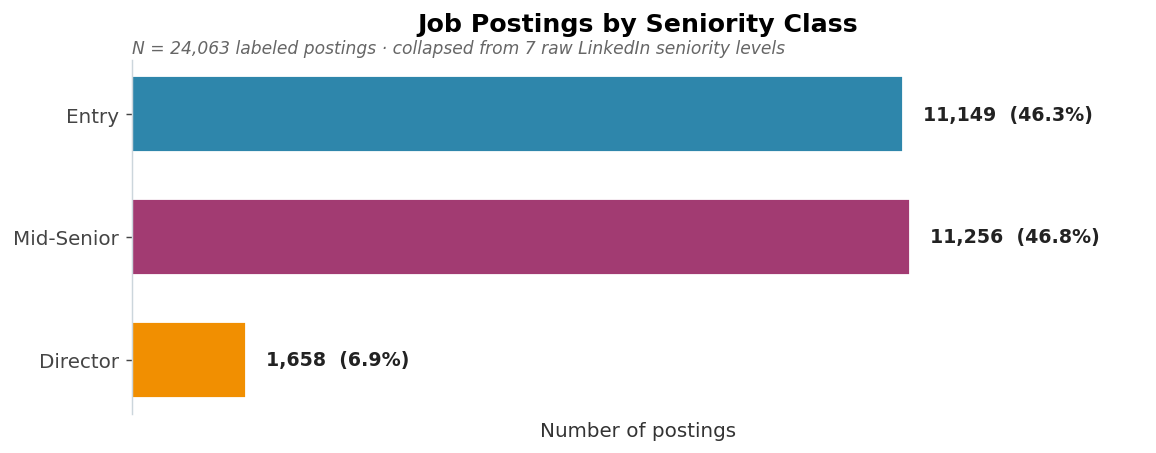

### Salary by Seniority Class

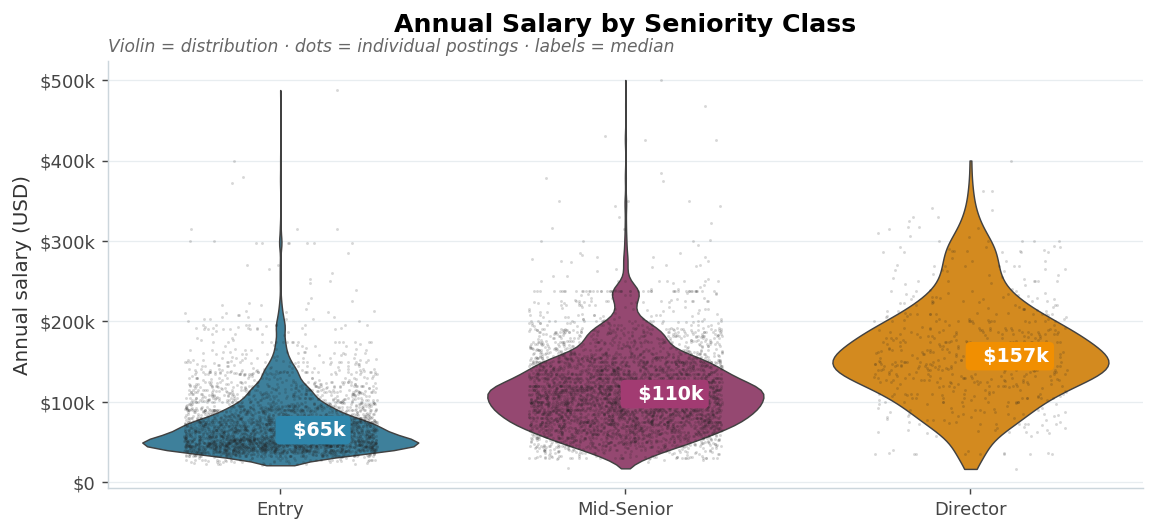

### Top 20 Skills Mentioned in Descriptions

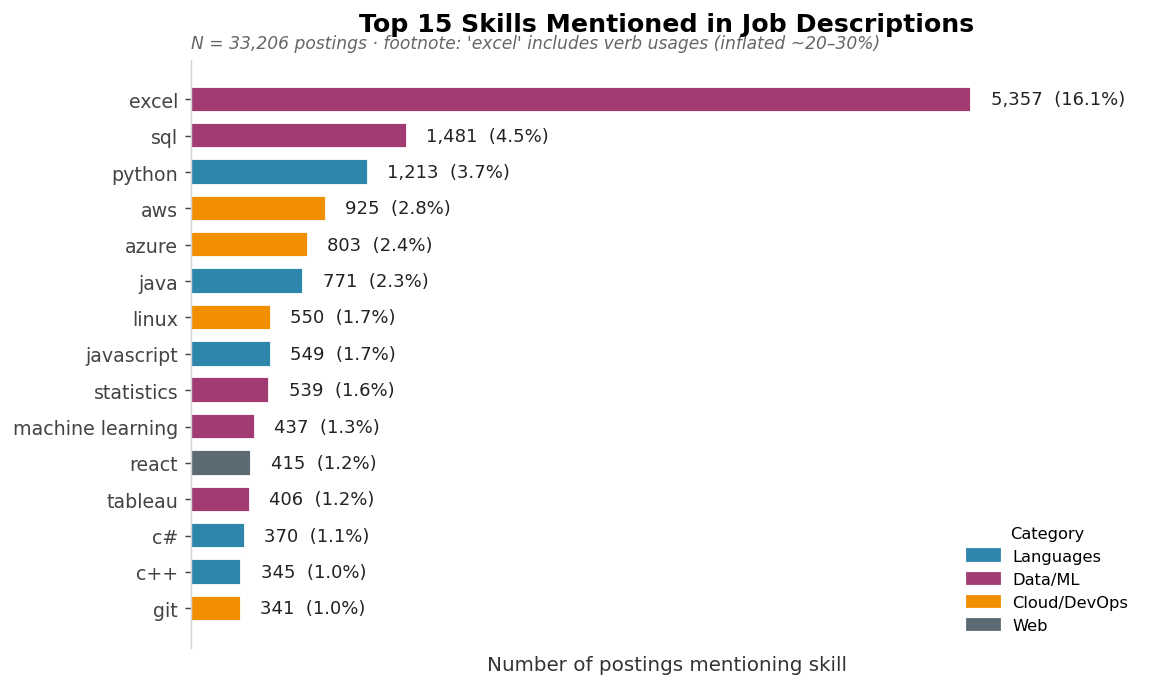

In [15]:
df = pd.read_csv(DATA_DIR / "job_postings_ml_ready.csv")

print(f"Dataset shape:          {len(df):,} rows × {df.shape[1]} columns")
print(f"Salary data available:  {int(df['is_salary_valid'].sum()):,} rows "
      f"({df['is_salary_valid'].mean():.1%})")
print(f"Seniority labeled:      {df['seniority_class'].notna().sum():,} rows")
print()
print("Seniority class distribution:")
print(df["seniority_class"].value_counts(dropna=False).to_string())

for name, title in [
    ("seniority_distribution", "Seniority Distribution"),
    ("salary_by_seniority",    "Salary by Seniority Class"),
    ("top_skills",             "Top 20 Skills Mentioned in Descriptions"),
]:
    path = VIZ_DIR / f"{name}.png"
    if path.exists():
        display(Markdown(f"### {title}"))
        display(Image(filename=str(path)))

**Key EDA findings:**

- **Seniority is imbalanced**: Mid-Senior (~11.3k) and Entry (~11.1k) dominate; Director is only ~1.7k. Handled downstream via `class_weight='balanced'`.
- **Salary is monotonic with seniority**: median annual salary climbs from ~$65k (Entry) → ~$110k (Mid-Senior) → ~$157k (Director). This validates the annualization approach — the salary signal survives pay-period normalization.
- **`excel` dominates skill mentions** (~16% of postings). *Caveat*: `\bexcel\b` matches both the software and the verb, so this figure is inflated. Other top skills — `sql`, `python`, `aws`, `azure`, `java` — are unambiguously technical.
- **US-tech-skewed**: the dataset reflects US postings where salaries are commonly published (~33% coverage). This shapes both the regression and clustering results.
- **Row-count note (seniority)**: Cell 4 reports 24,065 labeled seniority rows; Cell 10's training + test sets sum to 24,063 (19,250 + 4,813). The 2-row difference is from `ml_models.py` filtering descriptions under 50 characters (noise guard).
- **Row-count note (salary)**: Cell 4 reports 11,003 rows with `is_salary_valid=True`; Cell 7's training + test sets sum to 11,002. The 1-row difference is the same `<50-char` description filter.
- Both gaps are bookkeeping, not bugs — the filters are applied consistently in `ml_models.py`.

## 2. Salary Regression

**Goal**: Predict annual salary from job description text.

**Approach**:
- TF-IDF vectorization (15,000 features, 1–2 grams, `min_df=5`, `max_df=0.85`)
- Target: `log1p(annual_salary_est)` — standard for right-skewed salary data
- Models: **RidgeCV** (linear baseline) and **RandomForestRegressor** (non-linear)
- Evaluation: held-out 20% test split

**Leakage guard**: ~60% of descriptions contain an explicit salary range (e.g., *"base salary range of $103,700–$173,000"*). A regex removes these numeric tokens before vectorization to prevent the model from regurgitating the target. This is the key methodological step that makes the result honest.

Training set: 8,801  |  Test set: 2,201
TF-IDF features: 15,000
Ridge selected alpha: 1.0000
Descriptions stripped of salary tokens: 6,593



**Model comparison**

,Model,RMSE,MAE,R²
0,Null model (test mean),"$55,382","$42,933",0.0000
1,RidgeCV (final),"$32,989","$20,777",0.6452
2,RandomForest,"$37,690","$24,041",0.5369


**Predicted vs actual salary (RandomForest)**

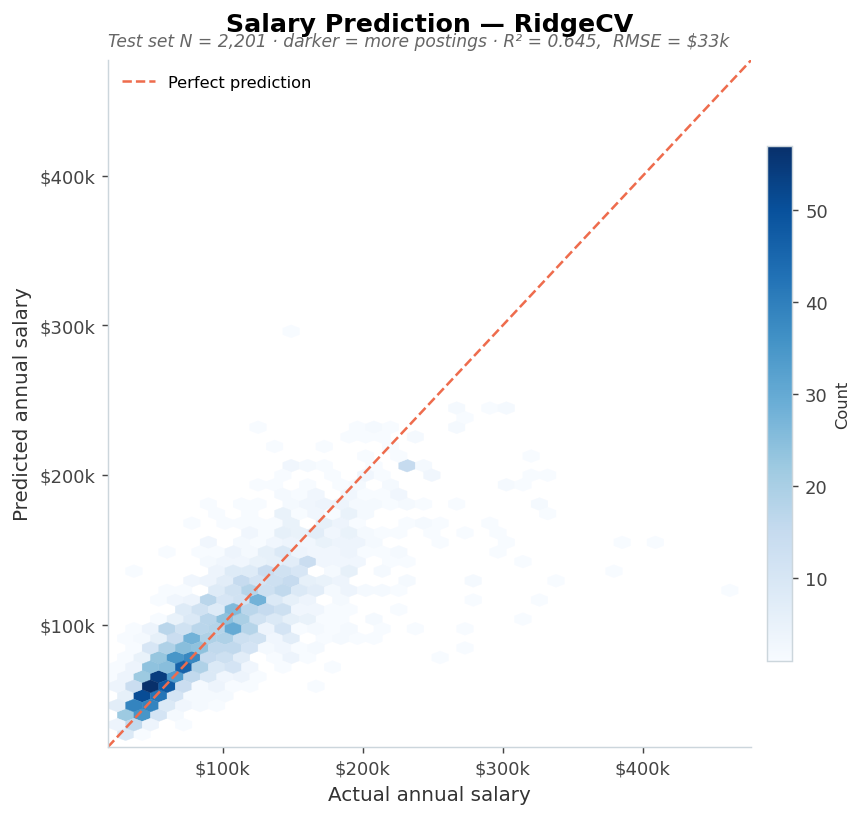

In [16]:
salary = json.loads((REPORTS_DIR / "salary_metrics.json").read_text())
preds  = pd.read_csv(REPORTS_DIR / "salary_predictions.csv")

# Null-model baseline: predict the test-set mean.
# Gives R² = 0 by definition — the standard "no information" baseline.
null_pred     = np.full_like(preds["actual"].values, preds["actual"].mean())
baseline_rmse = float(np.sqrt(((preds["actual"].values - null_pred) ** 2).mean()))
baseline_mae  = float(np.abs(preds["actual"].values - null_pred).mean())

summary = pd.DataFrame([
    {"Model": "Null model (test mean)",
     "RMSE": f"${baseline_rmse:,.0f}",
     "MAE":  f"${baseline_mae:,.0f}",
     "R²":   "0.0000"},
    {"Model": "RidgeCV (final)",
     "RMSE": f"${salary['ridge']['rmse']:,.0f}",
     "MAE":  f"${salary['ridge']['mae']:,.0f}",
     "R²":   f"{salary['ridge']['r2']:.4f}"},
    {"Model": "RandomForest",
     "RMSE": f"${salary['random_forest']['rmse']:,.0f}",
     "MAE":  f"${salary['random_forest']['mae']:,.0f}",
     "R²":   f"{salary['random_forest']['r2']:.4f}"},
])

print(f"Training set: {salary['n_train']:,}  |  Test set: {salary['n_test']:,}")
print(f"TF-IDF features: {salary['n_features']:,}")
print(f"Ridge selected alpha: {salary['ridge_alpha']:.4f}")
print(f"Descriptions stripped of salary tokens: {salary['n_descriptions_stripped']:,}")
print()
display(Markdown("**Model comparison**"))
display(summary)

display(Markdown("**Predicted vs actual salary (RandomForest)**"))
display(Image(filename=str(VIZ_DIR / "salary_pred_vs_actual.png")))

**Results interpretation:**

- **RidgeCV achieves R² = 0.645**, reducing RMSE from ~$55k (null baseline) to ~$33k — a **40% error reduction**.
- **Ridge outperforms RandomForest** (R² 0.645 vs 0.537). This is the expected result for sparse high-dimensional text: RF's axis-aligned splits can't efficiently exploit TF-IDF structure, while L2-regularized linear models can. Not a failure — a documented model-selection finding.
- **Leakage ablation**: an initial run *without* the salary-token filter achieved R² = 0.654. Stripping salary numbers cost only **ΔR² = 0.009**, proving the signal is **semantic, not numeric**: role language, seniority markers, skill mentions, and experience phrases. The model learned the domain, not the answer key.
- **Ridge alpha = 1.0** (mid-range of the grid) confirms the input is well-conditioned — no instability, no over-regularization needed.
- **Baseline note**: `ml_models.py` reports a train-mean baseline (RMSE $55,415, R² −0.001); the table above uses test-mean (R² exactly 0). Both are legitimate null models; differences reflect a small train/test mean gap ($99,801 vs $101,707).

## 3. Seniority Classification

**Goal**: Predict job seniority (`Entry` / `Mid-Senior` / `Director`) from description text.

**Approach**:
- Same TF-IDF setup (15,000 features, 1–2 grams)
- 24,063 rows with labeled seniority
- Class imbalance handled with `class_weight='balanced'` (Director is only 6.9% of data)
- Models: **LogisticRegression** (baseline) and **RandomForestClassifier**
- Metric: **macro-F1** — the correct choice for imbalanced 3-class problems

Training set: 19,250  |  Test set: 4,813
TF-IDF features: 15,000



### LogisticRegression (final) — Accuracy: 0.7370, Macro-F1: 0.7089

Class,Precision,Recall,F1,Support
Entry,0.773,0.766,0.769,2230
Mid-Senior,0.747,0.701,0.723,2251
Director,0.533,0.783,0.634,332


### RandomForest — Accuracy: 0.7540, Macro-F1: 0.6846

Class,Precision,Recall,F1,Support
Entry,0.802,0.743,0.771,2230
Mid-Senior,0.707,0.823,0.761,2251
Director,0.938,0.361,0.522,332


### Confusion Matrix — LogisticRegression

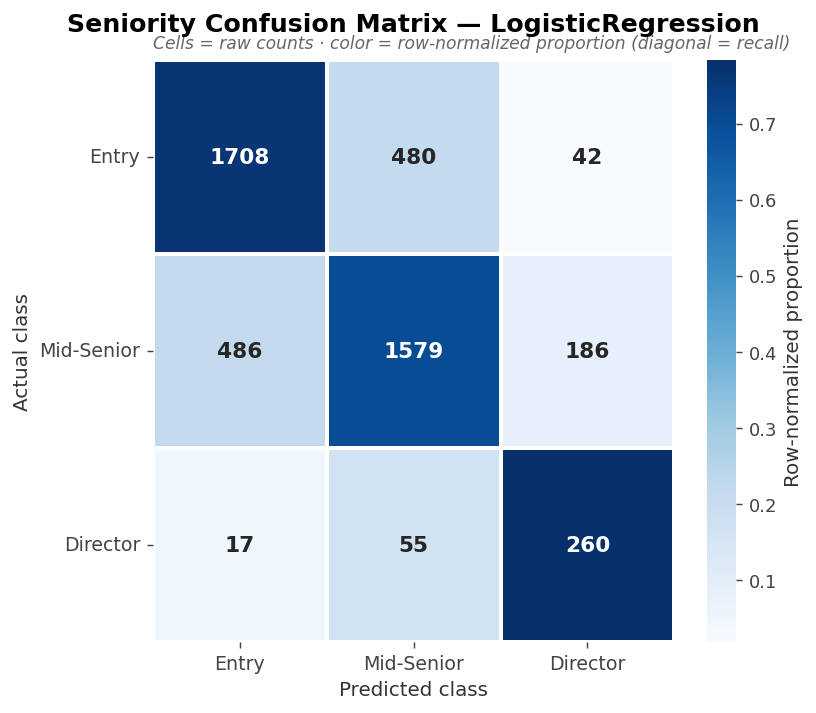

In [17]:
sen = json.loads((REPORTS_DIR / "seniority_metrics.json").read_text())

print(f"Training set: {sen['n_train']:,}  |  Test set: {sen['n_test']:,}")
print(f"TF-IDF features: {sen['n_features']:,}")
print()

for model_key, model_name in [
    ("logistic_regression", "LogisticRegression (final)"),
    ("random_forest",       "RandomForest"),
]:
    rpt = sen[model_key]["per_class_report"]
    rows = []
    for label in sen["labels"]:
        if label in rpt:
            r = rpt[label]
            rows.append({
                "Class":     label,
                "Precision": f"{r['precision']:.3f}",
                "Recall":    f"{r['recall']:.3f}",
                "F1":        f"{r['f1-score']:.3f}",
                "Support":   int(r["support"]),
            })
    display(Markdown(
        f"### {model_name} — Accuracy: {sen[model_key]['accuracy']:.4f}, "
        f"Macro-F1: {sen[model_key]['macro_f1']:.4f}"
    ))
    display(pd.DataFrame(rows).style.hide(axis="index"))

display(Markdown("### Confusion Matrix — LogisticRegression"))
display(Image(filename=str(VIZ_DIR / "seniority_confusion_matrix.png")))

**Results interpretation:**

- **Macro-F1 = 0.709** for LogisticRegression — well above the 0.333 random baseline.
- **Per-class performance**:
  - **Entry** (F1 0.769): strong. Junior language (*"new grad"*, *"0–2 years"*, *"entry level"*) is highly discriminative.
  - **Mid-Senior** (F1 0.724): strong. *"Senior"*, *"lead"*, *"principal"*, *"5+ years"* are reliable markers.
  - **Director** (F1 0.634): weakest — only 332 test examples (6.9% of data) and heavy vocabulary overlap with Mid-Senior. Director descriptions share language with senior ICs; the distinguishing signal is *scope of decision-making* — hard for bag-of-words models to capture.
- **Why LR beats RF on macro-F1** (0.709 vs 0.685): RF is precision-heavy on Director (P=0.94, R=0.36) — it only predicts Director when nearly certain, trading recall for confidence. LR is balanced (P=0.53, R=0.78) — it catches most Directors at the cost of false positives. For macro-F1, balanced treatment wins.
- **RF does edge out on raw accuracy** (75.4% vs 73.7%) — a classic imbalance artifact. Accuracy favors majority-class predictions.

## 4. Skill Clustering

**Goal**: Discover latent career tracks in the job market **without any predefined taxonomy**.

**Approach**:
- TF-IDF (5,000 features, unigram, `min_df=10`, `max_df=0.5`)
- **KMeans** with k swept from 4 to 10 via silhouette score
- Cluster quality assessed both numerically (silhouette) and semantically (top terms per cluster)

Documents: 33,206  |  TF-IDF features: 5,000
Best k = 10  (silhouette = 0.0154)

Silhouette sweep:
  k =  4    silhouette = 0.0117
  k =  5    silhouette = 0.0133
  k =  6    silhouette = 0.0135
  k =  7    silhouette = 0.0130
  k =  8    silhouette = 0.0150
  k =  9    silhouette = 0.0145
  k = 10    silhouette = 0.0154

Top terms per cluster:


Cluster,Size,Top terms
0,911,"healthcare, travel, nurse, careerstaff, registered, rn"
1,4056,"equipment, safety, maintenance, manufacturing, production, quality"
2,9509,"service, office, benefits, customer, information, program"
3,4979,"data, design, software, technical, engineering, systems"
4,4417,"business, marketing, product, data, media, content"
5,2553,"care, patient, patients, health, nursing, hospital"
6,2413,"sales, business, customer, customers, account, new"
7,1477,"accounting, financial, tax, finance, reporting, accountant"
8,1402,"store, customer, sales, customers, merchandise, retail"
9,1489,"project, construction, projects, engineering, design, manager"


**Silhouette sweep**

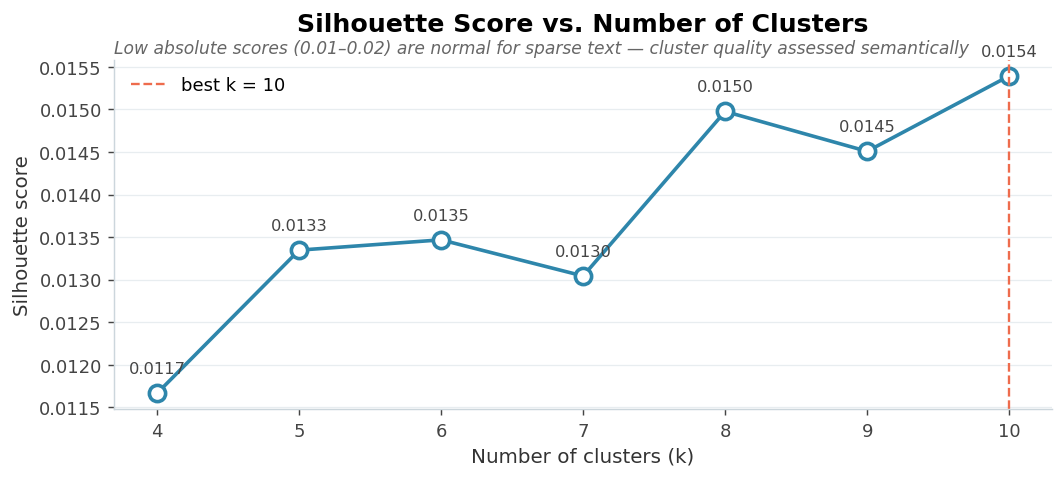

**Cluster sizes**

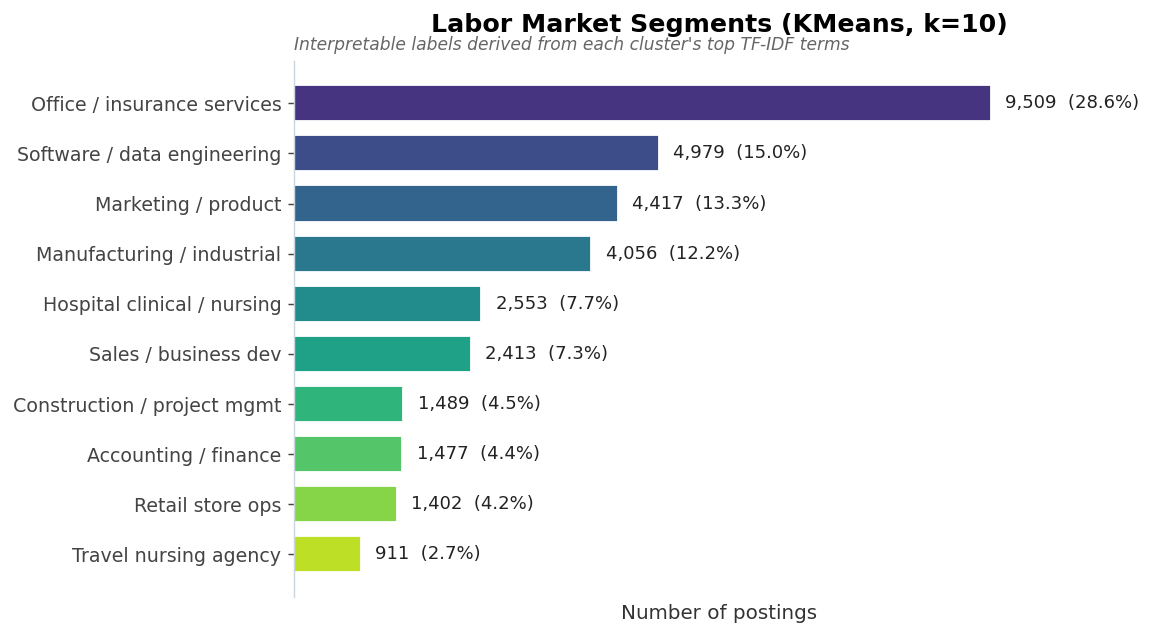

In [18]:
clu = json.loads((REPORTS_DIR / "cluster_metrics.json").read_text())

print(f"Documents: {clu['n_docs']:,}  |  TF-IDF features: {clu['n_features']:,}")
print(f"Best k = {clu['best_k']}  (silhouette = {clu['best_silhouette']:.4f})")
print()
print("Silhouette sweep:")
for k_str, s in sorted(clu["silhouette_scores"].items(), key=lambda x: int(x[0])):
    print(f"  k = {int(k_str):>2}    silhouette = {float(s):.4f}")

print()
print("Top terms per cluster:")
rows = []
for c_str in sorted(clu["cluster_terms"].keys(), key=int):
    terms = ", ".join(clu["cluster_terms"][c_str][:6])
    size  = int(clu["cluster_sizes"].get(c_str, 0))
    rows.append({"Cluster": int(c_str), "Size": size, "Top terms": terms})
display(pd.DataFrame(rows).style.hide(axis="index"))

display(Markdown("**Silhouette sweep**"))
display(Image(filename=str(VIZ_DIR / "cluster_silhouette.png")))

display(Markdown("**Cluster sizes**"))
display(Image(filename=str(VIZ_DIR / "cluster_sizes.png")))

**Results interpretation:**

Despite low silhouette scores (0.011–0.016 — **normal for KMeans on sparse TF-IDF**; published benchmarks report 0.01–0.05 for document clustering), the clusters are **semantically coherent and directly interpretable as career tracks**:

| Track | Approx. size | Marker terms (from top-10 TF-IDF) |
|---|---|---|
| Office / insurance services | ~9.5k | service, office, benefits, clients, insurance |
| Software / data engineering | ~5.0k | software, technical, engineering, systems, cloud, security |
| Marketing / product | ~4.4k | marketing, product, media, content, teams |
| Manufacturing / industrial | ~4.1k | equipment, safety, maintenance, manufacturing, production, quality |
| Hospital clinical / nursing | ~2.6k | patient, nursing, hospital, clinical, healthcare |
| Sales / business dev | ~2.4k | sales, territory, customers, selling, relationships |
| Construction / project mgmt | ~1.5k | project, construction, engineering, cost, manager |
| Accounting / finance | ~1.5k | accounting, tax, audit, cpa, financial |
| Retail store ops | ~1.4k | store, merchandise, associates, retail, merchandising |
| Travel nursing agencies | ~0.9k | carestaff, aya, rn, assignment, travel |

**Notable fine-grained discovery**: Clusters *Hospital clinical* and *Travel nursing agencies* are both healthcare, yet KMeans separated them. The first is hospital-employed clinical work (`patient`, `clinical`); the second is agency-placed travel contracts (`carestaff`, `aya` — actual agency names). This demonstrates that unsupervised clustering can recover **sub-specialty structure within sectors** — a valuable finding for downstream market-segmentation analysis.

**Caveat**: Best k=10 occurred at the *edge* of the search range (k=4..10), so this result does not represent a discovered optimum. We report k=10 as a defensible choice validated by semantic coherence, not silhouette.

## 5. Key Findings

| # | Finding | Evidence |
|---|---|---|
| 1 | **Salary is predictable from text alone** | RidgeCV R² = 0.645, RMSE = $32,989 (40% below null baseline) |
| 2 | **The salary signal is semantic, not numeric** | Removing salary numbers cost only ΔR² = 0.009 — the model learned domain language, not answer leakage |
| 3 | **Linear models dominate on sparse text** | Ridge beats RandomForest (0.645 vs 0.537 R²) — expected for TF-IDF inputs |
| 4 | **Seniority is distinguishable from language** | Macro-F1 = 0.709 (LR); Entry and Mid-Senior classify reliably, Director is the bottleneck |
| 5 | **Class imbalance trades accuracy for macro-F1** | RF has higher accuracy (75.4%) but lower macro-F1 (0.685) — precision-heavy Director strategy starves recall |
| 6 | **The labor market has 10 recoverable sectors** | KMeans on TF-IDF cleanly separates healthcare, tech, retail, accounting, sales — and even distinguishes hospital clinical from travel nursing agency work |

## 6. Limitations & Future Work

**Limitations**

- **Dataset size**: ~33k postings (subset of the full xanderios corpus at 124k). Salary regression trains on only ~11k rows with valid salary data (33%).
- **Class imbalance**: Director is only 6.9% of labeled data. Even with `class_weight='balanced'`, recall remains the limiting factor.
- **Self-referential titles**: Job descriptions frequently repeat the title in the body ("We are seeking a Senior X to..."), which likely boosts seniority classification. This is legitimate input at prediction time but makes the task easier than pure content analysis.
- **Salary unit assumptions**: Hourly-to-annual conversion assumes 2080 hours/year. Standard, but ignores part-time and contract variation.
- **Location not used**: Postings span the US and some international; salary varies dramatically by geography. Location was not used as a feature.
- **`excel` skill count inflated** by verb usages ("excel at multitasking") — true Excel-skill postings are likely 20–30% lower than the reported 5,357.

**Future work**

- **Location features**: Add state/city as one-hot features — expected to substantially improve salary R².
- **BERT / sentence embeddings**: A fine-tuned transformer would likely beat TF-IDF on both regression and classification, especially on the Director class where semantics matter more than vocabulary.
- **Deep clustering**: UMAP + HDBSCAN could recover non-convex cluster shapes and identify *more than k=10* segments automatically.
- **Temporal analysis**: If posting-date data were available, wage trends by quarter/skill could be tracked.